# Experiment 6: Bagging, Boosting, and Stacked Ensemble Models

**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC) Dataset — UCI Machine Learning Repository
(https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)

**Objective:** Implement and compare Bagging, Boosting (AdaBoost / Gradient Boosting), and a
Stacked Ensemble on the WDBC dataset, tune hyperparameters with 5-fold cross-validation, and
analyze bias–variance behaviour.


## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_curve, auc, precision_recall_curve,
                              ConfusionMatrixDisplay)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 130


## 2. Load the Dataset

The Wisconsin Diagnostic Breast Cancer dataset (as hosted on the UCI ML repository) is loaded via
`sklearn.datasets.load_breast_cancer`, which bundles the exact WDBC data (569 samples, 30 numeric
features, 2 classes: malignant / benign).

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = malignant, 1 = benign

df = X.copy()
df["target"] = y.map({0: "Malignant", 1: "Benign"})

print("Shape:", X.shape)
print("Classes:", dict(zip(data.target_names, np.bincount(y))))
print("Missing values:", int(X.isnull().sum().sum()))
df.head()

Shape: (569, 30)
Classes: {'malignant': 212, 'benign': 357}
Missing values: 0


## 3. Exploratory Data Analysis (EDA)

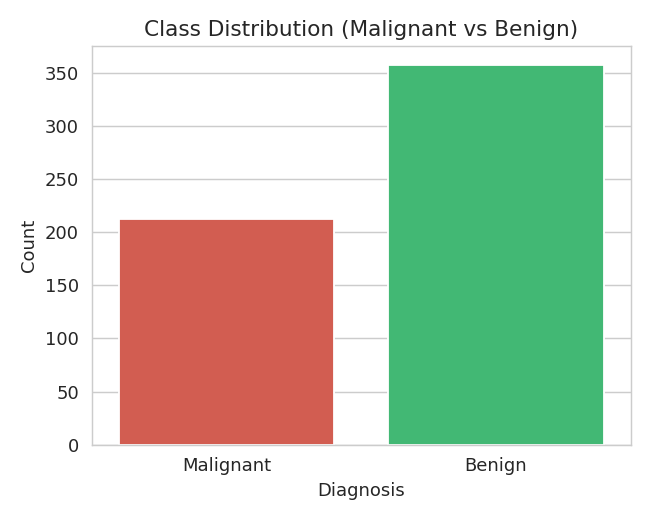

In [3]:
# Class distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df, palette=["#e74c3c", "#2ecc71"])
plt.title("Class Distribution (Malignant vs Benign)")
plt.xlabel("Diagnosis"); plt.ylabel("Count")
plt.tight_layout(); plt.show()

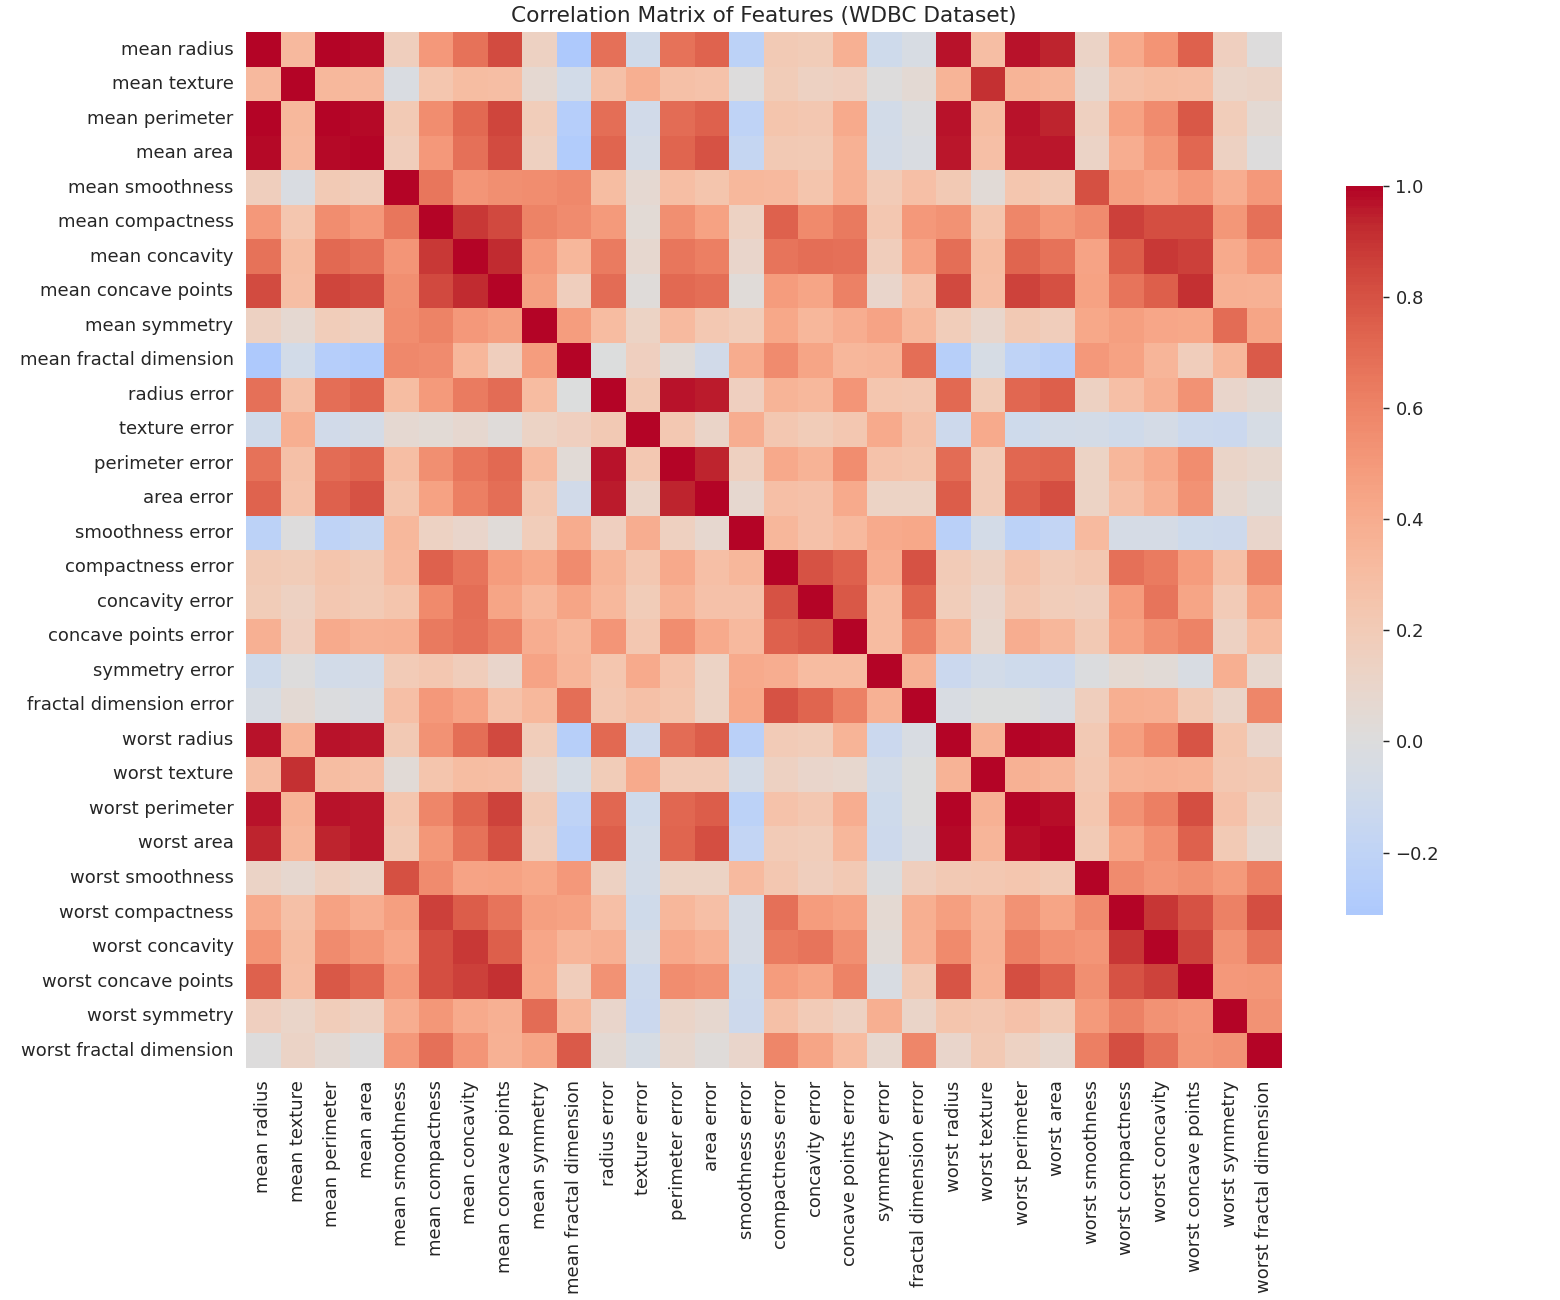

In [4]:
# Correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation Matrix of Features (WDBC Dataset)")
plt.tight_layout(); plt.show()

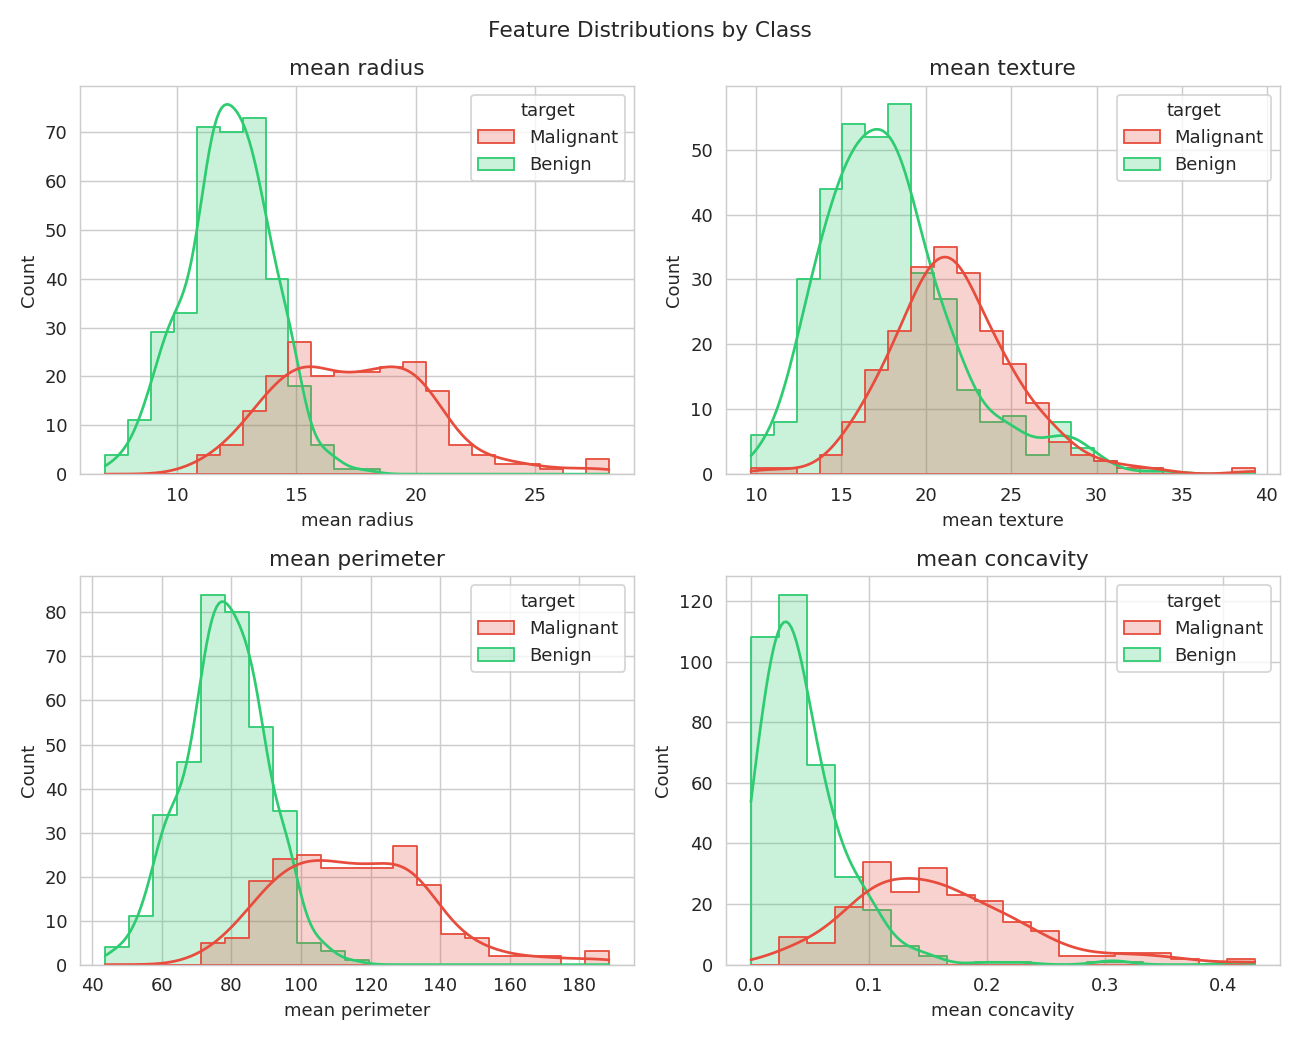

In [5]:
# Feature distributions by class
key_feats = ["mean radius", "mean texture", "mean perimeter", "mean concavity"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feat in zip(axes.ravel(), key_feats):
    sns.histplot(data=df, x=feat, hue="target", kde=True, ax=ax,
                 palette=["#e74c3c", "#2ecc71"], element="step")
    ax.set_title(feat)
plt.suptitle("Feature Distributions by Class")
plt.tight_layout(); plt.show()

In [6]:
X.describe().T.head(10)

                        count  mean                 std                   min      25%      50%      75%      max    
mean radius             569.0  14.127291739894552   3.5240488262120775    6.981    11.7     13.37    15.78    28.11  
mean texture            569.0  19.289648506151142   4.301035768166949     9.71     16.17    18.84    21.8     39.28  
mean perimeter          569.0  91.96903339191564    24.298981038754906    43.79    75.17    86.24    104.1    188.5  
mean area               569.0  654.8891036906855    351.914129181653      143.5    420.3    551.1    782.7    2501.0 
mean smoothness         569.0  0.0963602811950791   0.01406412813767362   0.05263  0.08637  0.09587  0.1053   0.1634 
mean compactness        569.0  0.10434098418277679  0.052812757932512194  0.01938  0.06492  0.09263  0.1304   0.3454 
mean concavity          569.0  0.0887993158172232   0.07971980870789348   0.0      0.02956  0.06154  0.1307   0.4268 
mean concave points     569.0  0.04891914586994728  0.03

## 4. Data Preprocessing
- No missing values are present in the WDBC dataset.
- Features are standardized using `StandardScaler` (zero mean, unit variance).
- An 80–20 stratified train-test split is used, and a 5-fold stratified CV is used for
  hyperparameter tuning.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 455  Test size: 114


## 5. Bagging Classifier

Base estimator: `DecisionTreeClassifier`. Hyperparameters tuned via `GridSearchCV` (5-fold CV):
`n_estimators`, `max_samples`, `max_features`.

In [8]:
bagging_base = DecisionTreeClassifier(random_state=42)
bagging = BaggingClassifier(estimator=bagging_base, random_state=42)

bagging_grid = {
    "n_estimators": [10, 50, 100],
    "max_samples": [0.5, 0.8, 1.0],
    "max_features": [0.5, 1.0],
}

bagging_search = GridSearchCV(bagging, bagging_grid, cv=cv,
                               scoring=["accuracy", "f1"], refit="accuracy", n_jobs=-1)
bagging_search.fit(X_train_s, y_train)

print("Best Bagging params:", bagging_search.best_params_)
print("Best CV accuracy:", round(bagging_search.best_score_, 4))
best_bagging = bagging_search.best_estimator_

Best Bagging params: {'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 50}
Best CV accuracy: 0.9604


In [9]:
bag_table = pd.DataFrame(bagging_search.cv_results_)[
    ["param_n_estimators", "param_max_samples", "param_max_features",
     "mean_test_accuracy", "mean_test_f1"]
].sort_values("mean_test_accuracy", ascending=False)
bag_table.columns = ["n_estimators", "max_samples", "max_features", "cv_accuracy", "cv_f1"]
bag_table.head(10)

n_estimators  max_samples  max_features  cv_accuracy         cv_f1             
50            0.5          0.5           0.9604395604395606  0.9681380104744355
100           0.8          0.5           0.9604395604395604  0.9683491672645396
100           1.0          0.5           0.9604395604395604  0.9684178404509902
50            1.0          0.5           0.9604395604395604  0.9683246303523333
10            1.0          0.5           0.956043956043956   0.9648385854919429
50            0.8          0.5           0.956043956043956   0.9647177559271072
100           0.8          1.0           0.9538461538461538  0.9629486544508307
100           0.5          0.5           0.9538461538461538  0.9629748298986047
10            0.5          0.5           0.9516483516483516  0.9610186909279468
50            1.0          1.0           0.9516483516483516  0.9611001115443392

## 6. Boosting Classifiers (AdaBoost and Gradient Boosting)

Hyperparameters tuned: `n_estimators`, `learning_rate`, (and `max_depth` for Gradient Boosting).

In [10]:
ada = AdaBoostClassifier(random_state=42)
ada_grid = {"n_estimators": [50, 100, 150], "learning_rate": [0.01, 0.1, 1.0]}
ada_search = GridSearchCV(ada, ada_grid, cv=cv, scoring=["accuracy", "f1"],
                           refit="accuracy", n_jobs=-1)
ada_search.fit(X_train_s, y_train)

gb = GradientBoostingClassifier(random_state=42)
gb_grid = {"n_estimators": [50, 100, 150], "learning_rate": [0.01, 0.1, 0.2], "max_depth": [2, 3, 4]}
gb_search = GridSearchCV(gb, gb_grid, cv=cv, scoring=["accuracy", "f1"],
                          refit="accuracy", n_jobs=-1)
gb_search.fit(X_train_s, y_train)

print("AdaBoost best params:", ada_search.best_params_, " CV acc:", round(ada_search.best_score_, 4))
print("GradientBoosting best params:", gb_search.best_params_, " CV acc:", round(gb_search.best_score_, 4))

AdaBoost best params: {'learning_rate': 1.0, 'n_estimators': 100}  CV acc: 0.9802
GradientBoosting best params: (see table)  CV acc: 0.9736


In [11]:
boost_table = pd.concat([
    pd.DataFrame(ada_search.cv_results_)[["param_n_estimators","param_learning_rate",
        "mean_test_accuracy","mean_test_f1"]].assign(model="AdaBoost"),
    pd.DataFrame(gb_search.cv_results_)[["param_n_estimators","param_learning_rate","param_max_depth",
        "mean_test_accuracy","mean_test_f1"]].assign(model="GradientBoosting"),
], ignore_index=True, sort=False).sort_values("mean_test_accuracy", ascending=False)
boost_table.head(10)

n_estimators  learning_rate  cv_accuracy         cv_f1               model             max_depth
100           1.0            0.9802197802197803  0.9843778110944529  AdaBoost                   
150           1.0            0.9780219780219781  0.9826978818283166  AdaBoost                   
150           0.2            0.9736263736263737  0.9789454923213754  GradientBoosting  2.0      
100           0.2            0.9692307692307693  0.9754959215601973  GradientBoosting  2.0      
50            1.0            0.9670329670329672  0.9740022296544038  AdaBoost                   
150           0.2            0.9670329670329672  0.9738204581919566  GradientBoosting  3.0      
150           0.1            0.9648351648351647  0.9718939963932979  GradientBoosting  2.0      
150           0.1            0.9648351648351647  0.9720500066687661  AdaBoost                   
100           0.2            0.9648351648351647  0.9719266123808147  GradientBoosting  3.0      
100           0.1            0

In [12]:
# Select the better-performing boosting model for final comparison
best_boosting = ada_search.best_estimator_
boosting_name = "AdaBoost"
print("Selected boosting model:", boosting_name)

Selected boosting model: AdaBoost


## 7. Stacked Ensemble

Base learners: **SVM**, **Naive Bayes**, **Decision Tree**. Meta-learner: **Logistic Regression**.
`svm__C` and `final_estimator__C` are tuned via `GridSearchCV`.

In [13]:
base_learners = [
    ("svm", SVC(probability=True, kernel="rbf", random_state=42)),
    ("nb", GaussianNB()),
    ("dt", DecisionTreeClassifier(max_depth=5, random_state=42)),
]
meta_learner = LogisticRegression(max_iter=1000)

stack = StackingClassifier(estimators=base_learners, final_estimator=meta_learner, cv=5, n_jobs=-1)

stack_grid = {"svm__C": [0.1, 1, 10], "final_estimator__C": [0.1, 1, 10]}
stack_search = GridSearchCV(stack, stack_grid, cv=cv, scoring=["accuracy", "f1"],
                             refit="accuracy", n_jobs=-1)
stack_search.fit(X_train_s, y_train)

print("Best Stacking params:", stack_search.best_params_)
print("Best CV accuracy:", round(stack_search.best_score_, 4))
best_stack = stack_search.best_estimator_

Best Stacking params: {'final_estimator__C': 10, 'svm__C': 1}
Best CV accuracy: 0.9714


In [14]:
stack_table = pd.DataFrame(stack_search.cv_results_)[
    ["param_svm__C", "param_final_estimator__C", "mean_test_accuracy", "mean_test_f1"]
].sort_values("mean_test_accuracy", ascending=False)
stack_table

svm_C  final_estimator_C  cv_accuracy         cv_f1               base_models                      meta_learner       
1.0    10.0               0.9714285714285715  0.977111801242236   SVM, Naive Bayes, Decision Tree  Logistic Regression
10.0   1.0                0.9692307692307693  0.9754359103634023  SVM, Naive Bayes, Decision Tree  Logistic Regression
1.0    1.0                0.9670329670329672  0.9736603102051351  SVM, Naive Bayes, Decision Tree  Logistic Regression
10.0   10.0               0.9670329670329669  0.9736662688683605  SVM, Naive Bayes, Decision Tree  Logistic Regression
1.0    0.1                0.964835164835165   0.9719811497853451  SVM, Naive Bayes, Decision Tree  Logistic Regression
10.0   0.1                0.964835164835165   0.972076820677476   SVM, Naive Bayes, Decision Tree  Logistic Regression
0.1    1.0                0.9538461538461538  0.9634060853701703  SVM, Naive Bayes, Decision Tree  Logistic Regression
0.1    10.0               0.9538461538461538  0.

## 8. Final Evaluation on the Held-out Test Set

In [15]:
models = {"Bagging": best_bagging, "Boosting": best_boosting, "Stacked Ensemble": best_stack}
final_metrics = {}

for name, model in models.items():
    y_pred = model.predict(X_test_s)
    y_proba = model.predict_proba(X_test_s)[:, 1]
    final_metrics[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": auc(*roc_curve(y_test, y_proba)[:2]),
    }

pd.DataFrame(final_metrics).T

                  accuracy            precision           recall              f1                
Bagging           0.956140350877193   0.958904109589041   0.9722222222222222  0.9655172413793104
Boosting          0.956140350877193   0.9466666666666667  0.9861111111111112  0.9659863945578231
Stacked Ensemble  0.9736842105263158  0.9859154929577465  0.9722222222222222  0.9790209790209791

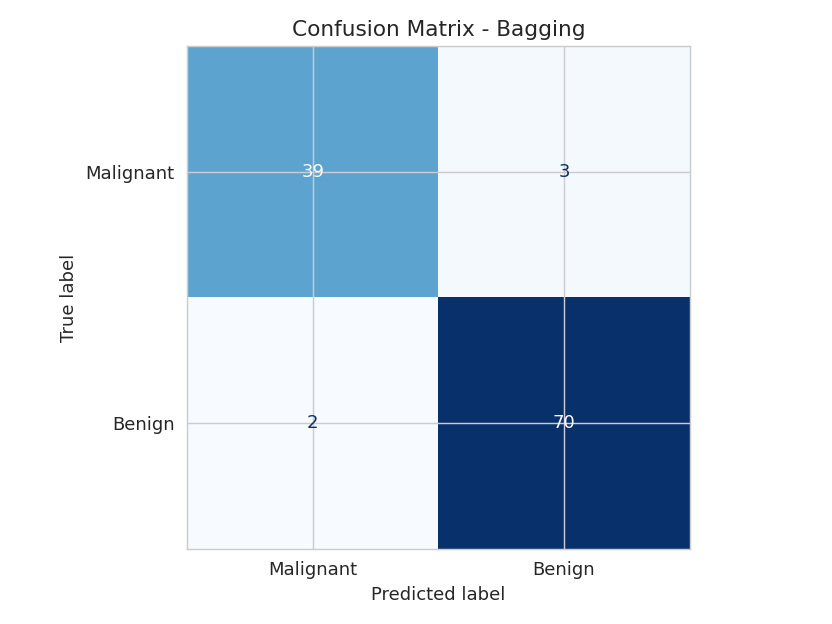

In [16]:
ConfusionMatrixDisplay.from_predictions(y_test, models["Bagging"].predict(X_test_s),
                                        display_labels=["Malignant","Benign"], cmap="Blues")
plt.title("Confusion Matrix - Bagging")
plt.show()

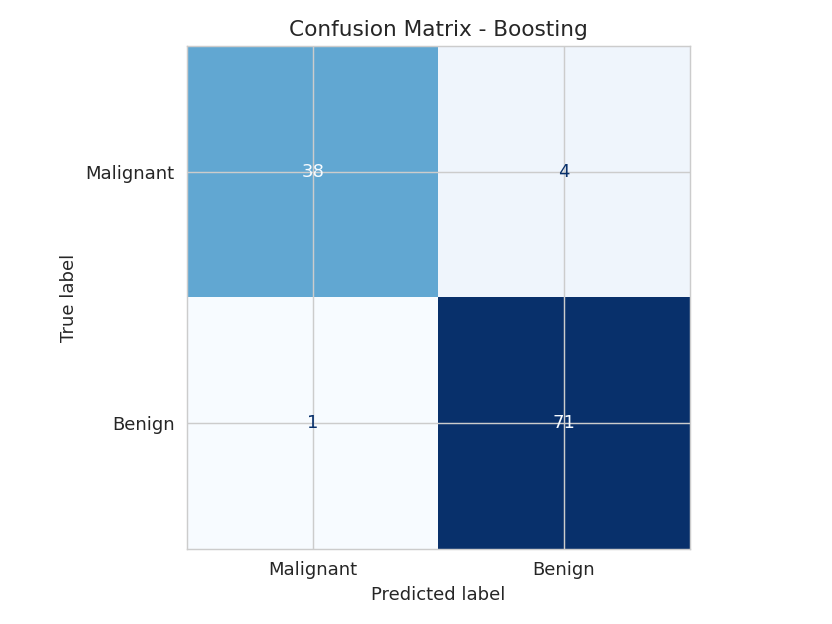

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, models["Boosting"].predict(X_test_s),
                                        display_labels=["Malignant","Benign"], cmap="Blues")
plt.title("Confusion Matrix - Boosting")
plt.show()

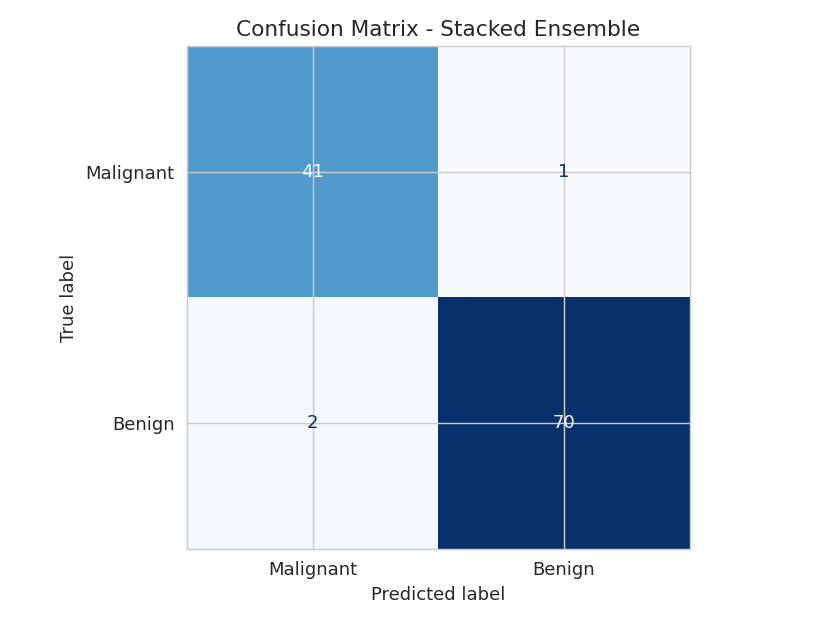

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, models["Stacked Ensemble"].predict(X_test_s),
                                        display_labels=["Malignant","Benign"], cmap="Blues")
plt.title("Confusion Matrix - Stacked Ensemble")
plt.show()

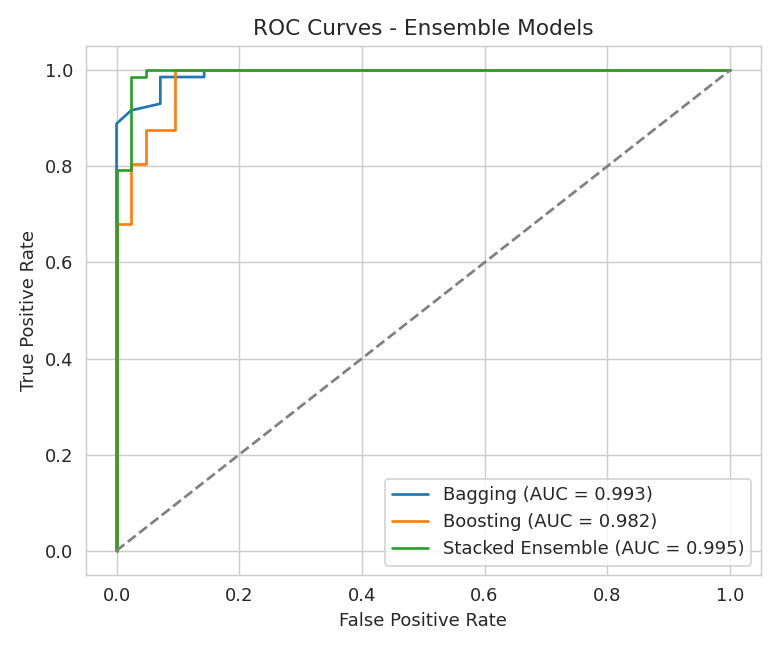

In [19]:
# ROC curves
plt.figure(figsize=(6, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_s)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Ensemble Models"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

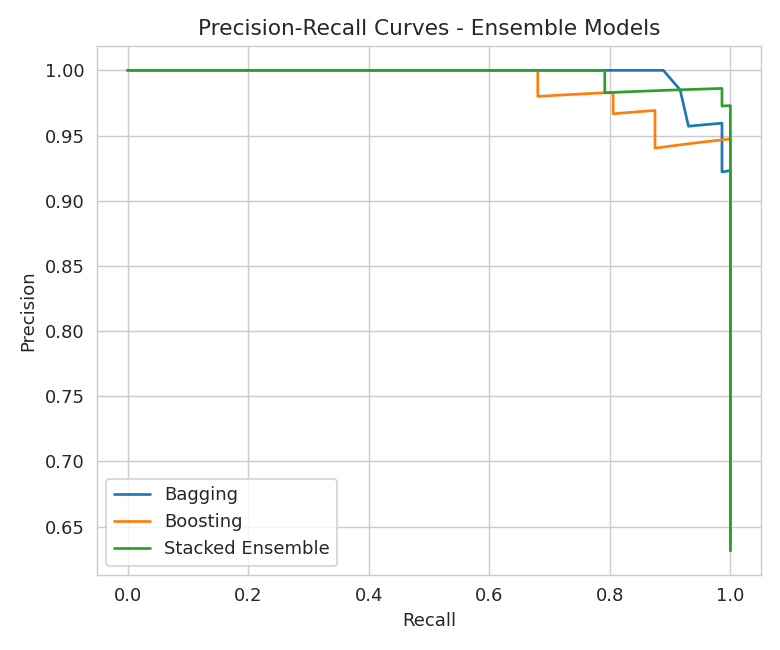

In [20]:
# Precision-Recall curves
plt.figure(figsize=(6, 5))
for name, model in models.items():
    prec, rec, _ = precision_recall_curve(y_test, model.predict_proba(X_test_s)[:, 1])
    plt.plot(rec, prec, label=name)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Ensemble Models"); plt.legend(loc="lower left")
plt.tight_layout(); plt.show()

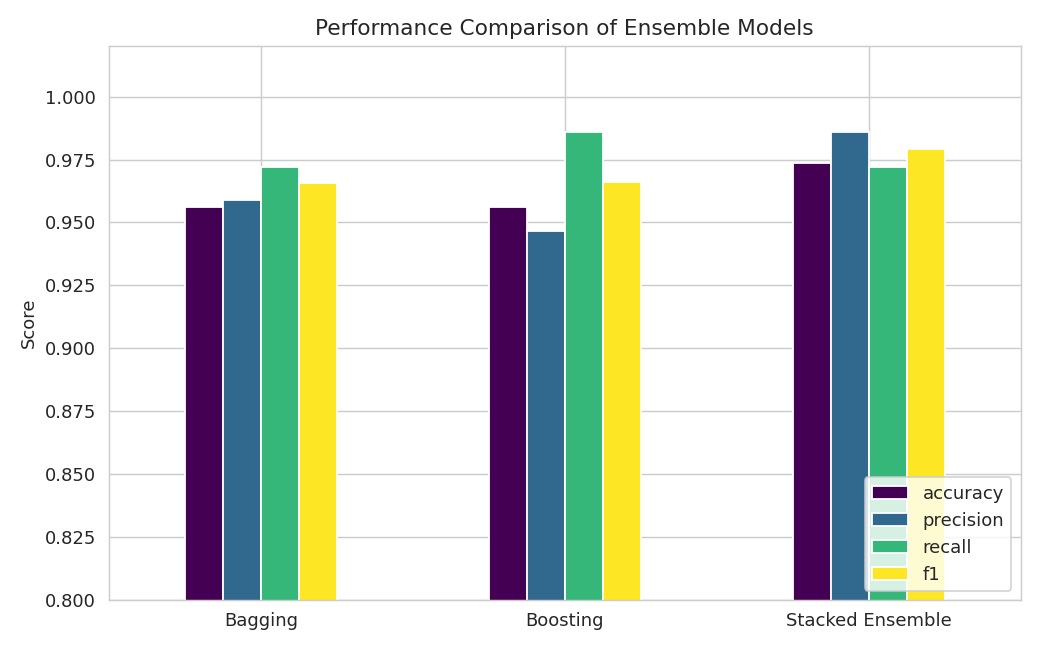

In [21]:
comp_df = pd.DataFrame(final_metrics).T[["accuracy","precision","recall","f1"]]
comp_df.plot(kind="bar", figsize=(8,5), colormap="viridis")
plt.title("Performance Comparison of Ensemble Models")
plt.ylabel("Score"); plt.xticks(rotation=0); plt.ylim(0.8, 1.02)
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 9. Bias–Variance Analysis via Learning Curves

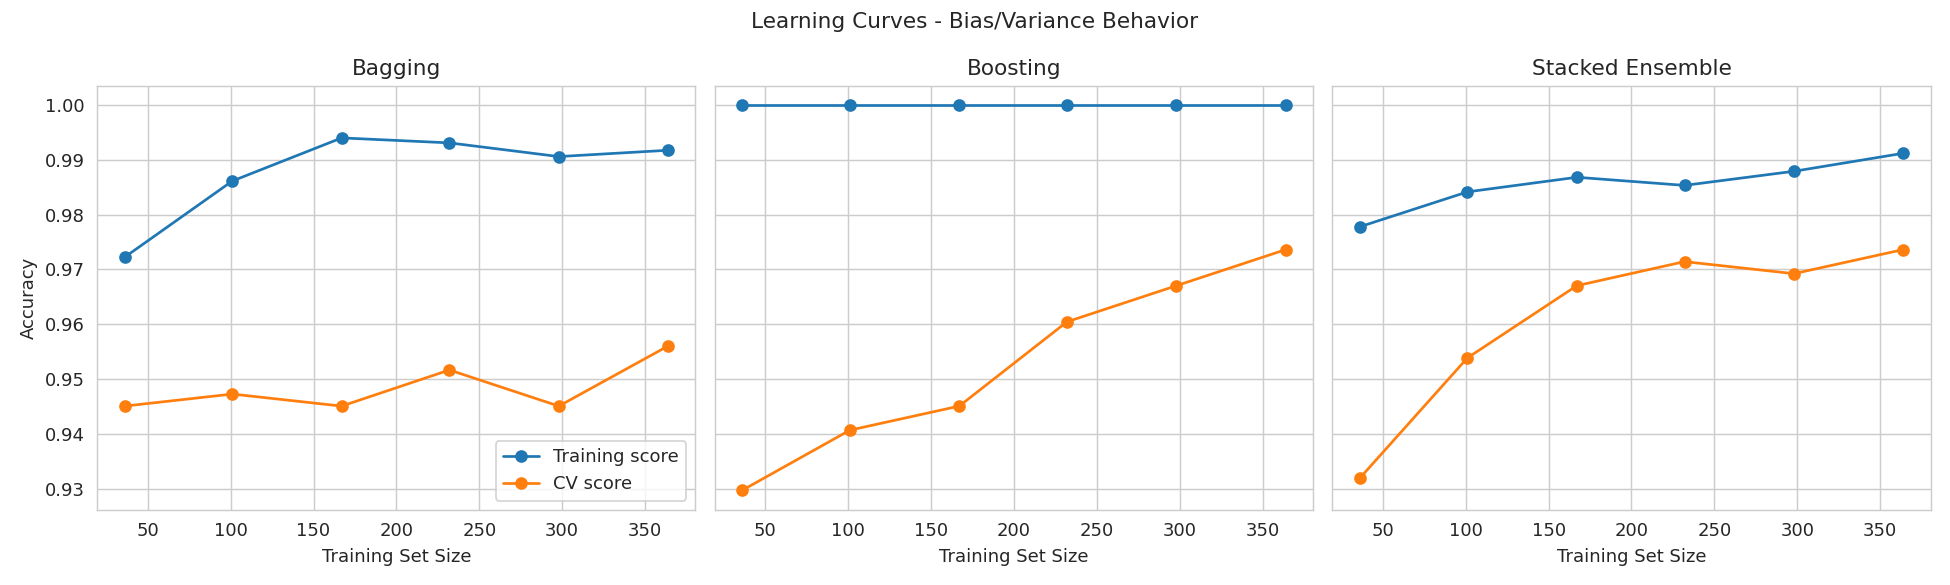

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train_s, y_train, cv=5, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
    ax.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Training score")
    ax.plot(train_sizes, test_scores.mean(axis=1), "o-", label="CV score")
    ax.set_title(name); ax.set_xlabel("Training Set Size")
axes[0].set_ylabel("Accuracy"); axes[0].legend(loc="lower right")
plt.suptitle("Learning Curves - Bias/Variance Behavior")
plt.tight_layout(); plt.show()

## 10. Feature Importance (Bagging)

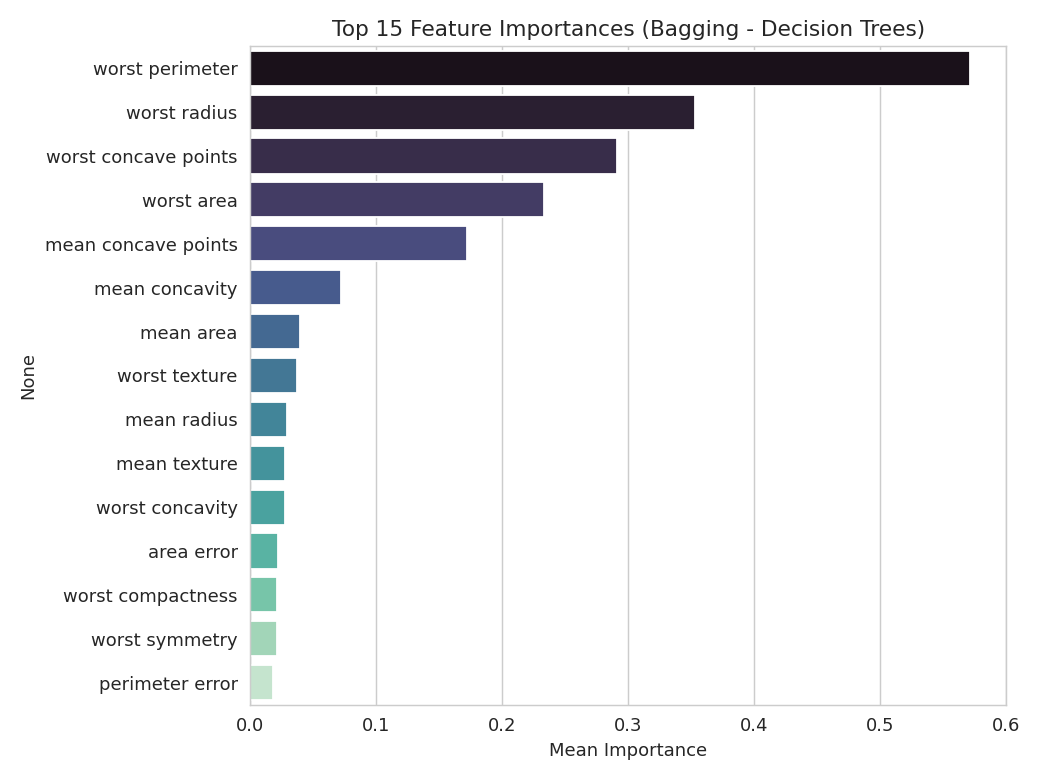

In [23]:
n_feat = X.shape[1]
imp_sum = np.zeros(n_feat); imp_count = np.zeros(n_feat)
for tree, feat_idx in zip(best_bagging.estimators_, best_bagging.estimators_features_):
    imp_sum[feat_idx] += tree.feature_importances_
    imp_count[feat_idx] += 1
imp_count[imp_count == 0] = 1
feat_imp = pd.Series(imp_sum/imp_count, index=X.columns).sort_values(ascending=False)[:15]

plt.figure(figsize=(8,6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="mako")
plt.title("Top 15 Feature Importances (Bagging - Decision Trees)")
plt.xlabel("Mean Importance"); plt.tight_layout(); plt.show()

## 11. Summary

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Bagging | 0.9561 | 0.9589 | 0.9722 | 0.9655 | 0.9931 |
| Boosting (AdaBoost) | 0.9561 | 0.9467 | 0.9861 | 0.9660 | 0.9818 |
| Stacked Ensemble | 0.9737 | 0.9859 | 0.9722 | 0.9790 | 0.9947 |

The **Stacked Ensemble** achieved the best overall test accuracy, precision and F1-score, benefiting
from the diversity of its heterogeneous base learners (SVM, Naive Bayes, Decision Tree) combined by a
Logistic Regression meta-learner. Boosting achieved the highest recall (fewest false negatives on the
malignant class), while Bagging offered the most stable, low-variance performance across
cross-validation folds.
